In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
data = pd.read_csv("/home/um40/LB2_project_Group_1/Data_preparation/Cleaned_merged_dataset.tsv", sep='\t')
print(data.shape)
pd.crosstab(data["length"], data["class"])

(9728, 9)


class,0,1
length,,
40,2,0
42,1,0
44,1,0
45,2,0
46,2,3
...,...,...
8799,1,0
12345,1,0
18141,1,0


First of all we have checked how many different lenghts our data has, in the dataset taken in consideration of 9728 entries there are present 1687 different lengths. So the first step done was to have a look and understand the values of principal summary statistics like mean, median and variance.

In [4]:
# Soma descriptive statistics 
data.groupby('class')['length'].agg(['mean', 'median', 'var'])

,mean,median,var
class,,,
0,574.518205,425,487057.916171
1,398.953804,274,200611.839206


Is turned out that the negative class has an average length of 574 aa and the median value is 425, while for the positive class an average length of 400 aa and a median value 274. The means could be affected by outliers, but it seems there is a big difference in terms of length between the two groups, in fact the observed differences between the medians tells us that the positive proteins have a shorter overall length.

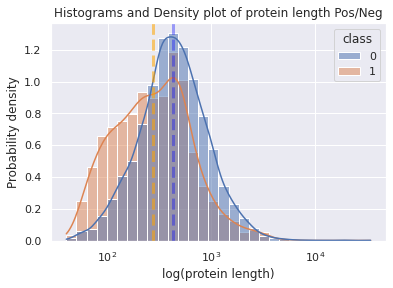

In [9]:
sns.set_theme(context='notebook', style = 'darkgrid',
    palette= "deep", font='sant-serif', font_scale=1,
    color_codes= True, rc=None)

med_pos = data[data["class"] == 1]["length"].median()
med_neg = data[data["class"] == 0]["length"].median()

fig, ax = plt.subplots()

# data2 = data[data["length"] <= 2500]
# I've normalized for each group of class, because the number of negative elements is much more of the positives
sns.histplot(data = data, stat="density", common_norm=False, element="bars", fill=True , x = "length", hue = "class",   log_scale = True, bins = 30, kde = True, ax = ax)

ax.axvline(med_pos, linestyle="--", linewidth = 3, color = "orange", alpha = 0.55)
ax.axvline(med_neg, linestyle="--", linewidth = 3, color = "blue", alpha = 0.35)

plt.xlabel("log(protein length)")
plt.ylabel("Probability density")
plt.title("Histograms and Density plot of protein length Pos/Neg")
#plt.savefig('Protein_Length_hist_dens.svg', format='svg', bbox_inches='tight')
plt.show()

For the plots a total of 30 bins was selected for the histograms to provide a balance between the resolution of the protein length distribution and the readability of the plots.
Looking at the histogram with the probability density plot, we had to normalize for each group of class, because these two are very different in terms of how many observations there are in them. In the case of negative (0) class data are distributed Normally, means all data are simmetric around a mean. While for positive data (1) seems that there are more shorts proteins and the distribution is not properly Normal, indicating that shorts proteins might make sense depending on whether or not they are positive.


They are not significative different, its not really discriminative in our case

No handles with labels found to put in legend.


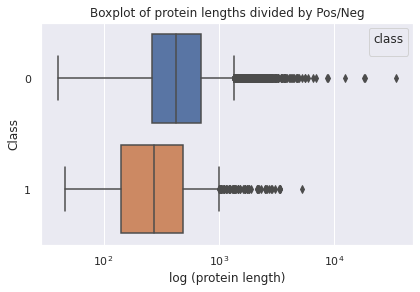

In [ ]:
sns.boxplot(data = data, y = "class", x = "length", orient = "h")
# legend and log_scale didnt work so i've done it manually
plt.xscale("log") 

plt.xlabel("log (protein length)")
plt.ylabel("Class")
plt.tight_layout()
plt.title("Boxplot of protein lengths divided by Pos/Neg")
plt.savefig('Protein_Length_box.svg', format='svg', bbox_inches='tight')


Plotting the boxplot of the two classes, here we can see what said before, the negative class (0) has more data, in fact the boxplot is further on the other, the mean and median are 574 and 425 respectively, while for the positive class are 400 and 274. Furthermore whiskers of the boxplot indicates that the negative class has more variance, that is also because there are a lot of different proteins there.

## By fold

Dividing by each fold we can have a look also to the test and training set and how data change between them.

In [3]:
data.groupby('fold')['length'].agg(['mean', 'median', 'var'])

,mean,median,var
fold,,,
-1,574.085817,412.0,1.168907e+06
1,541.378934,399.0,2.888237e+05
2,536.509955,406.0,2.398786e+05
3,570.109897,416.0,3.692560e+05
4,555.951157,426.0,2.432542e+05
5,544.662596,404.5,2.576537e+05


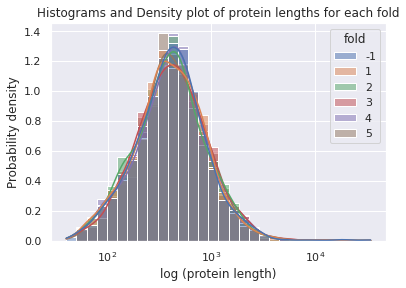

In [47]:
fig, ax = plt.subplots()
sns.histplot(data = data, stat="density", palette = "deep" ,common_norm=False, element="bars", fill=True , x = "length", hue = "fold",   log_scale = True, bins = 30, kde = True, ax = ax)

plt.xlabel("log (protein length)")
plt.ylabel("Probability density")
plt.title("Histograms and Density plot of protein lengths for each fold")
plt.show()

This is for be sure that each fold has the right composition in terms of number of elements insite it, and we can see that each fold is normally distributed so they are symmetrically distributed around the mean of that group, which is very similar across all groups.

Text(0.5, 1.0, 'Boxplot of protein lengths for each fold divided for Pos/Neg')

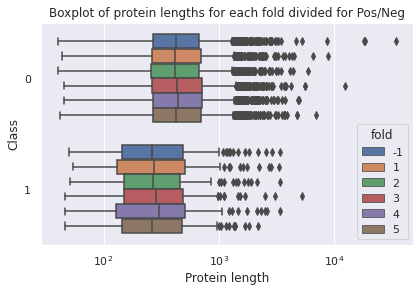

In [ ]:
sns.boxplot(data = data, y = "class", x = "length", hue = "fold", orient = "h")
# legend and log_scale didnt work so i've done it manually
plt.xscale("log") 
plt.legend(title="fold")
plt.ylabel("Class")
plt.xlabel("log (protein length)")
plt.tight_layout()
plt.title("Boxplot of protein lengths for each fold divided for Pos/Neg")

With the boxplot we can also see

## By kingdom

In [4]:
data.groupby('kingdom')['length'].agg(['mean', 'median', 'var'])

,mean,median,var
kingdom,,,
Fungi,488.335428,393.5,141380.909055
Metazoa,611.166541,430.0,711285.656994
Other,622.844340,458.5,360869.696034
Plants,466.187198,378.0,117346.368561


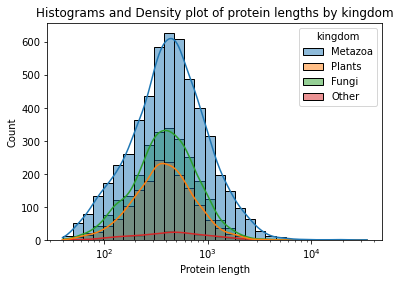

In [23]:
fig, ax = plt.subplots()

sns.histplot(data = data, x = "length", hue = "kingdom",  log_scale = True, bins = 30, kde = True, ax = ax)


plt.xlabel("Protein length")
plt.ylabel("Count")
plt.title("Histograms and Density plot of protein lengths by kingdom")
plt.show()

Text(0.5, 1.0, 'Boxplot of protein lengths for each kingdom divided for Pos/Neg')

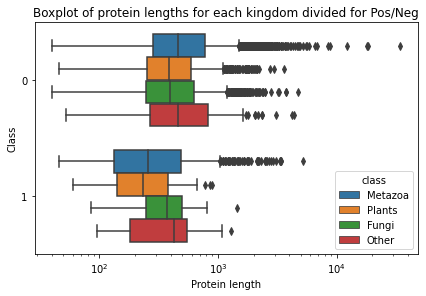

In [24]:
sns.boxplot(data = data, y = "class", x = "length", hue = "kingdom", orient = "h")
# legend and log_scale didnt work so i've done it manually
plt.xscale("log") 
plt.legend(title="class")
plt.ylabel("Class")
plt.xlabel("Protein length")
plt.tight_layout()
plt.title("Boxplot of protein lengths for each kingdom divided for Pos/Neg")